<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/60%20Starmons_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# 60-Qubit Star-Transmon Chip

Quantum Metal builds a 6 × 10 array of star-shaped transmons with asymmetric two-junction superconducting quantum interference devices (SQUIDs), in which 104 fixed coplanar-waveguide (CPW) links connect nearest-neighbor coupling pads. Twelve readout groups address five qubits each, while microwave-drive, flux, and readout lines reach 144 signal launchers distributed evenly across the four outer die edges.

## Layout parameters

| Parameter | Value or layout setting |
| --- | --- |
| Qubit array | 6 rows × 10 columns |
| Physical qubits | 60 star-shaped transmons |
| Josephson elements | Asymmetric two-junction SQUIDs |
| Fixed CPW links | 104 nearest-neighbor connections |
| Readout groups | 12 groups containing 5 qubits each |
| Microwave-drive and flux launchers | 120 total |
| Readout launchers | 24 total |
| Signal launchers per edge | 36 on each of the four die edges |
| Signal launcher pitch | 600 µm center to center |
| Ground-bond landing sites | 3 between each neighboring pair of signal launchers |
| Chip footprint | Automatically sized from the array span and perimeter fanout |

In [1]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [2]:
"""This script builds a 60-qubit star-transmon layout with native components."""

# --- Control Knobs ---
LAUNCHER_PITCH_MM = 0.600
CHEESE_KEEPOUT = "25um"
GROUND_STRAP_PITCH = "500um"
OUTPUT_FILENAME = "Starmon_60Q.gds"

# --- Imports ---
import sys
import urllib.request
from pathlib import Path
import logging
import warnings
import numpy as np
import pandas as pd
import networkx as nx
import gdstk
import matplotlib.pyplot as plt
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from qiskit_metal import designs, Dict, draw
import qiskit_metal as qm
from qiskit_metal.qlibrary.qubits.star_qubit import StarQubit
from qiskit_metal.qlibrary.qubits.SQUID_loop import SQUID_LOOP
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.lumped.cap_n_interdigital import CapNInterdigital
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.short_to_ground import ShortToGround
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.core import QComponent
from qiskit_metal.qlibrary.tlines.airbridge import Airbridge
from qiskit_metal.validation import validate, DEFAULT_RULES, SHAPE_RULES, Waiver
from qiskit_metal.validation.rules import GroundContinuityRule
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer

plt.rcParams["figure.dpi"] = 250

res_dir = Path("resources/wallraff_17q_main")
res_dir.mkdir(parents=True, exist_ok=True)

base_url = "https://raw.githubusercontent.com/qiskit-community/qiskit-metal/main/docs/circuit-examples/F.Small-quantum-chips/resources/wallraff_17q/"

for f in ["wallraff_17q.py", "geometry.json"]:
    urllib.request.urlretrieve(base_url + f, res_dir / f)

sys.path.insert(0, str(res_dir.resolve()))
import wallraff_17q as chip

## Layout specifications

The CPW center width and gap are 8.5 µm and 5.5 µm, following the nominal values in the supplied 17-qubit notebook. Four coupling pads face the cardinal directions, the readout pad faces northeast, and the SQUID faces southeast. Readout frequencies use a uniform phase-velocity length model with $v=1.2\times10^8$ m/s; the five nominal frequencies repeat on separate feedline groups. All submicron SQUID dimensions and crossover dimensions below are explicit nominal design values.

In [3]:
# --- Process Layers and Nominal Dimensions ---
layer_table = pd.DataFrame(
    [
        (1, "Nb", "Ground, qubit islands, CPWs, launcher electrodes"),
        (2, "Sacrificial resist", "Airbridge reflow scaffold pattern"),
        (3, "Al-Ti-Al", "Released signal crossings and ground straps"),
        (4, "Bridge contacts", "Landing/contact windows"),
        (5, "Al", "Lower SQUID electrode"),
        (6, "Al", "Upper SQUID electrode"),
        (7, "JJ overlap reference", "Derived Josephson-junction overlap areas"),
        (8, "Al", "Bandage contacts between SQUID electrodes and Nb"),
    ],
    columns=["GDS layer", "Material or mask", "Role"],
)
parameter_table = pd.DataFrame(
    [
        ("Array", "6 rows × 10 columns"),
        ("Site pitch x / y", "2.4 / 2.8 mm"),
        ("CPW center / gap", "8.5 / 5.5 um"),
        ("Readout and tee fillet", "50 um"),
        ("Control and feed-route fillet", "15 um"),
        ("SQUID branch width / loop gap", "200 nm / 10 um"),
        ("Nominal junction areas", "0.04 / 0.08 um²"),
        ("Signal crossing clear span", "110 um"),
        ("Ground strap clear span", "50 um"),
        ("Launcher metal inset", "100 um"),
        ("Native cheese holes / pitch", "25 × 25 um / 100 um"),
        ("Cheese hole edge setback", "100 um minimum"),
    ],
    columns=["Parameter", "Value"],
)
display(parameter_table)
display(layer_table)

,Parameter,Value
0,Array,6 rows × 10 columns
1,Site pitch x / y,2.4 / 2.8 mm
2,CPW center / gap,8.5 / 5.5 um
3,Readout and tee fillet,50 um
4,Control and feed-route fillet,15 um
5,SQUID branch width / loop gap,200 nm / 10 um
6,Nominal junction areas,0.04 / 0.08 um²
7,Signal crossing clear span,110 um
8,Ground strap clear span,50 um
9,Launcher metal inset,100 um


,GDS layer,Material or mask,Role
0,1,Nb,"Ground, qubit islands, CPWs, launcher electrodes"
1,2,Sacrificial resist,Airbridge reflow scaffold pattern
2,3,Al-Ti-Al,Released signal crossings and ground straps
3,4,Bridge contacts,Landing/contact windows
4,5,Al,Lower SQUID electrode
5,6,Al,Upper SQUID electrode
6,7,JJ overlap reference,Derived Josephson-junction overlap areas
7,8,Al,Bandage contacts between SQUID electrodes and Nb


## Qubits and automatic die footprint

The array span and routing margins set both chip dimensions before the edge launchers are placed. Each qubit has a 160 µm island radius, a 53 µm central region, and native capacitive coupling pads. A shared 100 µm inset positions every launcher's outer metal edge relative to its corresponding die edge.

The signal pitch sets the perimeter banks and row spacing, which gives a 28 × 26 mm footprint at the supplied settings. The 170 µm signal-pad width and two 70 µm clearances leave a 290 µm ground lane at a 600 µm pitch. The printed circuit board (PCB) bond shelf should follow the exported bond map; its die-to-board gap, bond-loop height, tool clearance, and enclosure modes are package-specific design inputs [4, 5].

In [4]:
# --- Automatic Footprint and Site Positions ---
QUBIT_ROWS = 6
QUBIT_COLUMNS = 10
column_pitch = 2.4
pad_pitch = LAUNCHER_PITCH_MM
assert pad_pitch >= 0.600, "Use at least 600 um to accommodate the ground-bond sites."
row_pitch = 6 * pad_pitch
readout_height = 3 * pad_pitch
bank_half_span = 35 * pad_pitch / 2
half_x = max((QUBIT_COLUMNS - 1) * column_pitch / 2 + 3.0, bank_half_span + 1.0)
half_y = max(
    (QUBIT_ROWS - 1) * row_pitch / 2 + 2.5 * pad_pitch + 2.5, bank_half_span + 1.0
)
chip_x = float(np.ceil(2 * half_x * 2) / 2)
chip_y = float(np.ceil(2 * half_y * 2) / 2)
design = designs.DesignPlanar(enable_renderers=False)
design.chips.main.size.size_x = f"{chip_x}mm"
design.chips.main.size.size_y = f"{chip_y}mm"
qubits = []
buses = []
couplers = []
resonators = []
launchpads = []
length_records = []
for row in range(QUBIT_ROWS):
    for col in range(QUBIT_COLUMNS):
        index = row * QUBIT_COLUMNS + col
        x = (col - (QUBIT_COLUMNS - 1) / 2) * column_pitch
        y = (row - (QUBIT_ROWS - 1) / 2) * row_pitch - 1.5 * pad_pitch
        q = StarQubit(
            design,
            f"Q{index}",
            options=Dict(
                pos_x=f"{x}mm",
                pos_y=f"{y}mm",
                radius="160um",
                center_radius="53um",
                gap_couplers="13um",
                gap_readout="6um",
                connector_length="40um",
                trap_offset="11um",
                junc_h="53um",
                number_of_connectors="4",
                resolution="32",
                cpw_width="8.5um",
                rotation_cpl1="90",
                rotation_cpl2="180",
                rotation_cpl3="270",
                rotation_cpl4="0",
                rotation_rdout="135",
                rotation_jj="45",
            ),
        )
        qubits.append(q)
print(f"{len(qubits)} qubits; footprint {chip_x:g} x {chip_y:g} mm.", flush=True)

60 qubits; footprint 28 x 26 mm.


In [5]:
# --- Asymmetric SQUID Electrodes ---
for q in qubits:
    name = q.name
    axis = 315
    angle = np.radians(axis)
    c = np.array([float(q.p.pos_x), float(q.p.pos_y)])
    unit = np.array([np.cos(angle), np.sin(angle)])
    # Keep the native island inside its 160 um disc; remove the single-JJ fork.
    table = design.qgeometry.tables["poly"]
    row = table.index[(table.component == q.id) & (table.name == "circle_inner")][0]
    table.at[row, "geometry"] = table.at[row, "geometry"].intersection(
        draw.Point(*c).buffer(0.160, quad_segs=16)
    )
    jt = design.qgeometry.tables["junction"]
    design.qgeometry.tables["junction"] = jt[jt.component != q.id].copy()
    tongue = draw.translate(
        draw.rotate(draw.rectangle(0.024, 0.014, 0.165, 0), axis, origin=(0, 0)), *c
    )
    q.add_qgeometry("poly", {"squid_contact": tongue}, layer=1)
    location = c + 0.172 * unit
    squid = SQUID_LOOP(
        design,
        f"SQUID_{name}",
        options=Dict(
            pos_x="0mm",
            pos_y="0mm",
            orientation="0",
            layer="5",
            squid_gap="10um",
            segment_a_width="200nm",
            segment_b_width="200nm",
            segment_d_length="10um",
        ),
    )
    local = squid.qgeometry_table("poly").geometry.union_all()
    squid.options.update(
        pos_x=f"{location[0]}mm", pos_y=f"{location[1]}mm", orientation=str(axis)
    )
    pieces = list(local.geoms)
    if pieces[0].centroid.x > pieces[1].centroid.x:
        pieces.reverse()
    lower, upper = pieces
    overlaps = []
    junctions = {}
    for i, (side, overlap) in enumerate(((-1, 0.0002), (1, 0.0004))):
        y = side * 0.0051
        upper = upper.union(
            draw.rectangle(
                0.0005 + overlap, 0.0002, 0.01275 + (0.0005 - overlap) / 2, y
            )
        )
        overlaps.append(draw.rectangle(overlap, 0.0002, 0.01275 - overlap / 2, y))
        junctions[f"JJ{i+1}"] = draw.LineString([(0.01275 - overlap, y), (0.01275, y)])
    lower = draw.translate(draw.rotate(lower, axis, origin=(0, 0)), *location)
    upper = draw.translate(draw.rotate(upper, axis, origin=(0, 0)), *location)
    masks = [
        draw.translate(draw.rotate(g, axis, origin=(0, 0)), *location) for g in overlaps
    ]
    jjs = {
        k: draw.translate(draw.rotate(g, axis, origin=(0, 0)), *location)
        for k, g in junctions.items()
    }
    pt = design.qgeometry.tables["poly"]
    design.qgeometry.tables["poly"] = pt[pt.component != squid.id].copy()
    squid.add_qgeometry("poly", {"lower_electrode": lower}, layer=5)
    squid.add_qgeometry("poly", {"upper_electrode": upper}, layer=6)
    squid.add_qgeometry(
        "poly", {f"overlap_{i+1}": g for i, g in enumerate(masks)}, layer=7
    )
    squid.add_qgeometry("junction", jjs, width=0.0002, layer=5)
    contacts = [draw.rectangle(0.004, 0.010), draw.rectangle(0.004, 0.010, 0.03225, 0)]
    contacts = [
        draw.translate(draw.rotate(g, axis, origin=(0, 0)), *location) for g in contacts
    ]
    squid.add_qgeometry("poly", {"bandages": draw.union(*contacts)}, layer=8)

print("SQUID loops", len(qubits), flush=True)

SQUID loops 60


## Nearest-neighbor links

The fixed CPW links connect the east and west pads of horizontal neighbors and the north and south pads of vertical neighbors. Qubit SQUIDs provide the flux-controlled elements. These links follow the local square-lattice connectivity used by the supplied design.

In [6]:
# --- Local Passive CPW Links ---
for row in range(QUBIT_ROWS):
    for col in range(QUBIT_COLUMNS):
        a = qubits[row * QUBIT_COLUMNS + col]
        neighbors = []
        if col + 1 < QUBIT_COLUMNS:
            neighbors.append(
                (qubits[row * QUBIT_COLUMNS + col + 1], "pin_cpl1", "pin_cpl3")
            )
        if row + 1 < QUBIT_ROWS:
            neighbors.append(
                (qubits[(row + 1) * QUBIT_COLUMNS + col], "pin_cpl2", "pin_cpl4")
            )
        for b, pa, pb in neighbors:
            route = RouteStraight(
                design,
                f"BUS_{a.name}_{b.name}",
                options=Dict(
                    trace_width="8.5um",
                    trace_gap="5.5um",
                    pin_inputs=Dict(
                        start_pin=Dict(component=a.name, pin=pa),
                        end_pin=Dict(component=b.name, pin=pb),
                    ),
                ),
            )
            buses.append(route)
print("Passive links", len(buses), flush=True)

Passive links 104


## Multiplexed readout

Each native `CoupledLineTee` couples a readout resonator to its feedline. The tee's secondary line ends in a ground short, while the qubit coupling pad provides the capacitive end of the quarter-wave resonator. Native `RouteMeander` components supply the resonator paths and 50 µm fillets; the length calculation includes the tee's secondary arm.

In [7]:
# --- Multiplexed Readout Hangers ---
frequencies = np.linspace(6.7, 7.5, 5)
phase_velocity = 1.2e8
for row in range(QUBIT_ROWS):
    for col in range(QUBIT_COLUMNS):
        index = row * QUBIT_COLUMNS + col
        q = qubits[index]
        x = float(q.p.pos_x)
        y = float(q.p.pos_y)
        tee = CoupledLineTee(
            design,
            f"CLT{index}",
            options=Dict(
                pos_x=f"{x+.7}mm",
                pos_y=f"{y+readout_height}mm",
                prime_width="8.5um",
                prime_gap="5.5um",
                second_width="8.5um",
                second_gap="5.5um",
                coupling_length="300um",
                coupling_space="8um",
                down_length="180um",
                fillet="50um",
                open_termination=False,
            ),
        )
        arm = tee.qgeometry_table("path").query("name == 'second_cpw'").iloc[0]
        arm_length = arm.geometry.length - (2 - np.pi / 2) * arm.fillet
        target = phase_velocity / (4 * frequencies[col % 5] * 1e9) * 1e3
        resonator = RouteMeander(
            design,
            f"RO_{index}",
            options=Dict(
                trace_width="8.5um",
                trace_gap="5.5um",
                fillet="50um",
                total_length=f"{target-arm_length}mm",
                pin_inputs=Dict(
                    start_pin=Dict(component=q.name, pin="pin_rdout"),
                    end_pin=Dict(component=tee.name, pin="second_end"),
                ),
                lead=Dict(start_straight="180um", end_straight="150um"),
                meander=Dict(spacing="240um", asymmetry="-500um"),
                prevent_short_edges="true",
            ),
        )
        couplers.append(tee)
        resonators.append(resonator)
        length_records.append(
            dict(
                qubit=q.name,
                target_GHz=frequencies[col % 5],
                length_mm=resonator.length + arm_length,
            )
        )
print("Readout resonators", len(resonators), flush=True)

Readout resonators 60


## Readout launchers and series input capacitors

Each row contains two independent groups of five resonators. A native two-terminal `CapNInterdigital` sits directly in the input center-conductor path, and a returning feedline brings the second port to the same outer die edge. Native routing helpers place signal crossings wherever these feedlines pass over local coupling links.

In [8]:
# --- Feedline Groups and Edge Launchpads ---
for row in range(QUBIT_ROWS):
    y = float(qubits[row * QUBIT_COLUMNS].p.pos_y) + readout_height
    for half, side in enumerate((-1, 1)):
        indices = list(
            range(row * QUBIT_COLUMNS + half * 5, row * QUBIT_COLUMNS + (half + 1) * 5)
        )
        if side == 1:
            indices.reverse()
        entry, exit = (
            ("prime_start", "prime_end") if side == -1 else ("prime_end", "prime_start")
        )
        tag = f"{row}_{half}"
        group = [couplers[i] for i in indices]
        cap = CapNInterdigital(
            design,
            f"CAP_{tag}",
            options=Dict(
                pos_x=f"{side*(chip_x/2-1.1)}mm",
                pos_y=f"{y}mm",
                orientation=str(side * 90),
                north_width="8.5um",
                north_gap="5.5um",
                south_width="8.5um",
                south_gap="5.5um",
                cap_width="10um",
                cap_gap="6um",
                cap_gap_ground="6um",
                finger_length="20um",
                finger_count="5",
                cap_distance="50um",
            ),
        )
        for label, py in (("IN", y), ("OUT", y + pad_pitch)):
            pad = LaunchpadWirebond(
                design,
                f"LP_FEED_{tag}_{label}",
                options=Dict(
                    pos_x=f"{side*(chip_x/2-.570)}mm",
                    pos_y=f"{py}mm",
                    orientation="0" if side == -1 else "180",
                    trace_width="8.5um",
                    trace_gap="5.5um",
                    lead_length="25um",
                    pad_width="170um",
                    pad_height="230um",
                    taper_height="240um",
                    pad_gap="70um",
                ),
            )
            launchpads.append(pad)
            if label == "IN":
                a, b, ap, bp = pad, cap, "tie", "south_end"
                pts = [a.pins[ap].middle, b.pins[bp].middle]
            else:
                a, b, ap, bp = group[-1], pad, exit, "tie"
                p0 = np.asarray(a.pins[ap].middle)
                p1 = np.asarray(b.pins[bp].middle)
                turnx = p0[0] - side * 0.20
                pts = [p0, np.array([turnx, y]), np.array([turnx, py]), p1]
            names = chip.draw_traced(
                design, f"FEED_{tag}_{label}", pts, over=("BUS_",), tag="ABF"
            )
            design.connect_pins(a.id, ap, design.components[names[0]].id, "start")
            design.connect_pins(design.components[names[-1]].id, "end", b.id, bp)
        joints = [(cap, "north_end", group[0], entry)]
        joints += [(a, exit, b, entry) for a, b in zip(group[:-1], group[1:])]
        for k, (a, ap, b, bp) in enumerate(joints):
            pts = [a.pins[ap].middle, b.pins[bp].middle]
            names = chip.draw_traced(
                design, f"FEED_{tag}_{k}", pts, over=("BUS_",), tag="ABF"
            )
            design.connect_pins(a.id, ap, design.components[names[0]].id, "start")
            design.connect_pins(design.components[names[-1]].id, "end", b.id, bp)
print("Readout launchers", len(launchpads), flush=True)

Readout launchers 24


## Perimeter drive and flux launchers

The middle six qubit columns use the bottom and top edges, while the outer two columns on either side use that side's edge. Each edge holds 36 signal ports at the selected pitch. The drive lines end open beside their qubits; the flux lines end in ground shorts beside the SQUIDs. Native routing helpers connect the path pieces and place crossovers where the control wiring crosses earlier lines.

In [9]:
# --- Perimeter Microwave and Flux Ports ---
# The middle six columns fan out to the top and bottom edges.
for col in range(2, QUBIT_COLUMNS - 2):
    for side, rows in (
        (-1, list(range(QUBIT_ROWS // 2 - 1, -1, -1))),
        (1, list(range(QUBIT_ROWS // 2, QUBIT_ROWS))),
    ):
        for local, row in enumerate(rows):
            q = qubits[row * QUBIT_COLUMNS + col]
            x, y = float(q.p.pos_x), float(q.p.pos_y)
            for kind in ("DRIVE", "FLUX"):
                slot = local * 2 + (kind == "FLUX")
                port_index = (col - 2) * 6 + slot
                px = (port_index - 17.5) * pad_pitch
                py = side * (chip_y / 2 - 0.570)
                pad = LaunchpadWirebond(
                    design,
                    f"LP_{kind}_{q.name}",
                    options=Dict(
                        pos_x=f"{px}mm",
                        pos_y=f"{py}mm",
                        orientation="90" if side == -1 else "270",
                        trace_width="8.5um",
                        trace_gap="5.5um",
                        lead_length="25um",
                        pad_width="170um",
                        pad_height="230um",
                        taper_height="240um",
                        pad_gap="70um",
                    ),
                )
                launchpads.append(pad)
                channel_x = x - 1.3 + 0.2 * slot
                pts = [
                    np.asarray(pad.pins.tie.middle),
                    [px, side * (chip_y / 2 - 0.900)],
                    [channel_x, side * (chip_y / 2 - 2.000)],
                ]
                if kind == "FLUX":
                    end = np.array([x + 0.235 / np.sqrt(2), y - 0.235 / np.sqrt(2)])
                    pts += [[channel_x, y - 0.65], [end[0], y - 0.65], end]
                else:
                    end = np.array([x - 0.21, y - 0.14])
                    pts += [[channel_x, end[1]], end]
                names = chip.draw_traced(
                    design,
                    f"{kind}_{q.name}",
                    pts,
                    over=("BUS_", "RO_", "CLT", "FEED_", "DRIVE_", "FLUX_"),
                    tag="ABCTRL",
                )
                design.connect_pins(
                    pad.id, "tie", design.components[names[0]].id, "start"
                )
                chip.terminate(
                    design,
                    f"{kind}END_{q.name}",
                    ShortToGround if kind == "FLUX" else OpenToGround,
                    names[-1],
                    at="end",
                )

# The outer two columns on each side share that edge with the readout ports.
for side, columns in ((-1, (1, 0)), (1, (8, 9))):
    for row in range(QUBIT_ROWS):
        row_center = (row - (QUBIT_ROWS - 1) / 2) * row_pitch
        for local, col in enumerate(columns):
            q = qubits[row * QUBIT_COLUMNS + col]
            x, y = float(q.p.pos_x), float(q.p.pos_y)
            for kind in ("DRIVE", "FLUX"):
                slot = local * 2 + (kind == "FLUX")
                px = side * (chip_x / 2 - 0.570)
                py = row_center + (slot - 2.5) * pad_pitch
                pad = LaunchpadWirebond(
                    design,
                    f"LP_{kind}_{q.name}",
                    options=Dict(
                        pos_x=f"{px}mm",
                        pos_y=f"{py}mm",
                        orientation="0" if side == -1 else "180",
                        trace_width="8.5um",
                        trace_gap="5.5um",
                        lead_length="25um",
                        pad_width="170um",
                        pad_height="230um",
                        taper_height="240um",
                        pad_gap="70um",
                    ),
                )
                launchpads.append(pad)
                lane_y = y - 1.0 + 0.2 * slot
                outer_x = side * (chip_x / 2 - 0.900)
                inner_x = side * ((QUBIT_COLUMNS - 1) * column_pitch / 2 + 0.800)
                pts = [
                    np.asarray(pad.pins.tie.middle),
                    [outer_x, py],
                    [inner_x, lane_y],
                ]
                if kind == "FLUX":
                    end = np.array([x + 0.235 / np.sqrt(2), y - 0.235 / np.sqrt(2)])
                    pts += [[end[0], lane_y], end]
                else:
                    end = np.array([x - 0.21, y - 0.14])
                    pts += [[x - 0.40, lane_y], [x - 0.40, end[1]], end]
                names = chip.draw_traced(
                    design,
                    f"{kind}_{q.name}",
                    pts,
                    over=("BUS_", "RO_", "CLT", "FEED_", "DRIVE_", "FLUX_"),
                    tag="ABCTRL",
                )
                design.connect_pins(
                    pad.id, "tie", design.components[names[0]].id, "start"
                )
                chip.terminate(
                    design,
                    f"{kind}END_{q.name}",
                    ShortToGround if kind == "FLUX" else OpenToGround,
                    names[-1],
                    at="end",
                )
print("Control launchers", len(launchpads) - 24, flush=True)

Control launchers 120


## Signal crossings and ground straps

Signal crossings use isolated niobium landings, sacrificial reflow patterns, elevated aluminium-titanium-aluminium spans, and contact windows. Ground straps use the same process layers, with both feet enclosed by existing ground metal. Native filleted-path sampling places the straps, and a spatial index rejects locations that conflict with other bridge masks; the accepted geometry is added in batches.

In [10]:
from qiskit_metal.qlibrary.core import QComponent
from qiskit_metal.qlibrary.tlines.airbridge import Airbridge

crossings = [c for c in design.components.values() if c.name.startswith("XO_")]
for old in list(design.components.values()):
    if not isinstance(old, Airbridge):
        continue
    name = "XO_" + old.name
    cx, cy = float(old.p.pos_x), float(old.p.pos_y)
    angle = float(old.p.orientation)
    length = float(old.p.crossover_length)
    feet_center = length / 2 + 0.0055
    peers = []
    for pin_name in ("a", "b"):
        net_id = old.pins[pin_name].net_id
        match = design.net_info[
            (design.net_info.net_id == net_id)
            & (design.net_info.component_id != old.id)
        ]
        for _, peer in match.iterrows():
            peers.append(
                (
                    pin_name,
                    design._components[int(peer.component_id)].name,
                    peer.pin_name,
                )
            )
    pin_points = {p: old.pins[p].points.copy() for p in ("a", "b")}
    design.delete_component(old.name)
    crossing = QComponent(
        design,
        name,
        options=Dict(
            pos_x=f"{cx}mm", pos_y=f"{cy}mm", orientation=str(angle), layer="1"
        ),
        make=False,
    )
    feet = draw.union(
        draw.rectangle(0.011, 0.011, -feet_center, 0),
        draw.rectangle(0.011, 0.011, feet_center, 0),
    )
    clearance = draw.union(
        draw.rectangle(0.022, 0.022, -feet_center, 0),
        draw.rectangle(0.022, 0.022, feet_center, 0),
    )
    span = draw.rectangle(2 * (feet_center + 0.005), 0.0085)
    scaffold = draw.rectangle(length + 0.001, 0.0195)
    contacts = draw.union(
        draw.rectangle(0.006, 0.005, -feet_center, 0),
        draw.rectangle(0.006, 0.005, feet_center, 0),
    )
    objects = draw.translate(
        draw.rotate([feet, clearance, span, scaffold, contacts], angle, origin=(0, 0)),
        cx,
        cy,
    )
    feet, clearance, span, scaffold, contacts = objects
    crossing.add_qgeometry("poly", {"base_landings": feet}, layer=1)
    crossing.add_qgeometry(
        "poly", {"landing_clearance": clearance}, layer=1, subtract=True
    )
    crossing.add_qgeometry("poly", {"reflow_scaffold": scaffold}, layer=2)
    crossing.add_qgeometry("poly", {"AlTiAl_overpass": span}, layer=3)
    crossing.add_qgeometry("poly", {"contacts": contacts}, layer=4)
    for p in ("a", "b"):
        middle = np.asarray(pin_points[p]).mean(axis=0)
        peer_name, peer_pin = next((n, pn) for pin, n, pn in peers if pin == p)
        route = design.components[peer_name]
        trace = route.qgeometry_table("path")
        if trace.empty:
            crossing.add_pin(p, np.asarray(pin_points[p]), width=0.011)
            continue
        coords = np.asarray(trace[~trace["subtract"]].iloc[0].geometry.coords)
        if np.linalg.norm(coords[-1] - middle) < np.linalg.norm(coords[0] - middle):
            coords = coords[::-1]
        normal = coords[1] - coords[0]
        normal /= np.linalg.norm(normal)
        crossing.add_pin(
            p,
            np.array([middle - 0.01 * normal, middle]),
            width=0.011,
            input_as_norm=True,
        )
    for p, peer_name, peer_pin in peers:
        design.connect_pins(crossing.id, p, design.components[peer_name].id, peer_pin)
    crossings.append(crossing)
print("PROCESS CROSSOVERS", len(crossings), flush=True)

PROCESS CROSSOVERS 488


## Perimeter ground-bond lands

Additional ground bonds between signal bonds reduce package-mediated crosstalk and lower the ground-connection inductance [4]. The three landing sites per gap are a layout allowance; the assembly drawing sets the actual PCB endpoints and wire loops. Native cheesing uses these positive ground polygons to keep the landing surfaces unperforated.

In [11]:
# --- Ground-Bond Landing Areas ---
port_records = []
for pad in launchpads:
    angle = int(float(pad.p.orientation)) % 360
    edge = {0: "left", 180: "right", 90: "bottom", 270: "top"}[angle]
    port_records.append(
        dict(
            component=pad.name,
            edge=edge,
            x_mm=float(pad.p.pos_x),
            y_mm=float(pad.p.pos_y),
        )
    )
port_table = pd.DataFrame(port_records)
ground_sheet = GroundContinuityRule(chip="main", layer=1)._ground_sheet(
    design, chip="main"
)
bond_lands = {}
bond_records = []
for edge, bank in port_table.groupby("edge"):
    horizontal = edge in ("bottom", "top")
    axis = "x_mm" if horizontal else "y_mm"
    bank = bank.sort_values(axis)
    positions = bank[axis].to_numpy()
    assert len(bank) == 36, edge
    assert np.min(np.diff(positions)) >= pad_pitch - 1e-9, edge
    for gap, middle in enumerate((positions[:-1] + positions[1:]) / 2):
        for site, offset in enumerate((-0.100, 0.000, 0.100)):
            if horizontal:
                bx = middle + offset
                by = (-1 if edge == "bottom" else 1) * (chip_y / 2 - 0.250)
                landing = draw.rectangle(0.075, 0.150, bx, by)
            else:
                bx = (-1 if edge == "left" else 1) * (chip_x / 2 - 0.250)
                by = middle + offset
                landing = draw.rectangle(0.150, 0.075, bx, by)
            assert ground_sheet.covers(landing.buffer(0.005)), (edge, gap, site)
            name = f"GND_{edge}_{gap}_{site}"
            bond_lands[name] = landing
            bond_records.append(dict(component=name, edge=edge, x_mm=bx, y_mm=by))
ground_bond_component = QComponent(design, "GroundBondLands", make=False)
ground_bond_component.add_qgeometry("poly", bond_lands, layer=1)
ground_bond_table = pd.DataFrame(bond_records)
assert len(ground_bond_table) == 420
print("36 signal launchers per edge; signal pitch", pad_pitch * 1000, "um.")
print(len(bond_lands), "ground-bond sites remain solid under native cheesing.")

36 signal launchers per edge; signal pitch 600.0 um.
420 ground-bond sites remain solid under native cheesing.


In [12]:
# --- Ground Straps Along the Filleted CPWs ---
if "GroundStraps" in design.components:
    design.delete_component("GroundStraps")

from shapely import STRtree, prepare
from qiskit_metal.qlibrary.tlines.airbridge import _fillet_centerline, _placements_along

ground_sheet = GroundContinuityRule(chip="main", layer=1)._ground_sheet(
    design, chip="main"
)
ground_regions = [
    p for p in getattr(ground_sheet, "geoms", [ground_sheet]) if p.area > 1e-4
]
ground_graph = nx.Graph()
ground_graph.add_nodes_from(range(len(ground_regions)))
safe_regions = [region.buffer(-0.001) for region in ground_regions]
prepare(safe_regions)
region_tree = STRtree(safe_regions)
bridge_spans = [
    c.qgeometry_table("poly").query("subtract == False").geometry.union_all()
    for c in crossings
]
span_tree = STRtree(bridge_spans)
pending_spans = []
ground_straps = []
ground_masks = {layer: {} for layer in range(1, 5)}
strap_pitch = float(design.parse_value(GROUND_STRAP_PITCH))
for route in list(design.components.values()):
    if not isinstance(route, (chip.PolylineCPW, RouteStraight, RouteMeander)):
        continue
    paths = route.qgeometry_table("path")
    points = np.asarray(paths[~paths["subtract"]].iloc[0].geometry.coords)
    steps = np.diff(points, axis=0)
    turns = steps[:-1, 0] * steps[1:, 1] - steps[:-1, 1] * steps[1:, 0]
    points = points[np.r_[True, np.abs(turns) > 1e-12, True]]
    radius = float(design.parse_value(route.options.get("fillet", "0um")))
    rounded = _fillet_centerline(points, radius)
    placements = _placements_along(rounded, strap_pitch, 0.100)
    for index, (cx, cy, angle) in enumerate(placements):
        feet_center = 0.0305
        feet = [draw.rectangle(0.011, 0.011, side * feet_center, 0) for side in (-1, 1)]
        span = draw.rectangle(0.071, 0.0085)
        scaffold = draw.rectangle(0.051, 0.0195)
        contacts = draw.union(
            *[draw.rectangle(0.006, 0.005, side * feet_center, 0) for side in (-1, 1)]
        )
        feet = draw.translate(draw.rotate(feet, angle, origin=(0, 0)), cx, cy)
        span, scaffold, contacts = draw.translate(
            draw.rotate([span, scaffold, contacts], angle, origin=(0, 0)), cx, cy
        )
        regions = []
        for foot in feet:
            matches = [
                int(i) for i in region_tree.query(foot) if safe_regions[i].covers(foot)
            ]
            if matches:
                regions.append(matches[0])
        if len(regions) != 2:
            continue
        envelope = draw.union(span, scaffold, *feet)
        if len(span_tree.query(envelope, predicate="dwithin", distance=0.003)):
            continue
        if any(envelope.distance(other) < 0.003 for other in pending_spans):
            continue
        name = f"GS_{route.name}_{index}"
        for layer, geometry in (
            (1, draw.union(*feet)),
            (2, scaffold),
            (3, span),
            (4, contacts),
        ):
            ground_masks[layer][name] = geometry
        ground_straps.append(name)
        ground_graph.add_edge(*regions)
        bridge_spans.append(envelope)
        pending_spans.append(envelope)
        if len(pending_spans) >= 32:
            span_tree = STRtree(bridge_spans)
            pending_spans.clear()
assert nx.is_connected(ground_graph), list(nx.connected_components(ground_graph))
ground_component = QComponent(design, "GroundStraps", make=False)
for layer, geometries in ground_masks.items():
    ground_component.add_qgeometry("poly", geometries, layer=layer)
print(
    f"{len(ground_straps)} ground straps connect all {len(ground_regions)} Nb ground regions."
)

3204 ground straps connect all 46 Nb ground regions.


## Native routing, geometry, and contact checks

Quantum Metal checks metal overlap, spacing, routing, and shapes. A separate graph verifies that the elevated ground straps connect every base-layer ground region, which supplies the reason for the native ground-continuity waiver. The checks below also measure all launcher footprints against the die perimeter and verify the readout lengths and bridge contacts.

The perimeter checks verify the signal pitch and the 100 µm metal-edge inset. Each adjacent signal pair has three 75 × 150 µm ground-bond landing sites spaced 100 µm apart; these areas lie inside existing ground metal and native cheesing keeps them solid. The bond map lists signal and ground landing centers in millimeters, while the GDS readback verifies that all ground landings contain metal. The nominal 75 µm landing width and 100 µm site pitch provide room for the 25 µm aluminium-wire guidance in [6].

In [13]:
# --- Geometry, Length, and Perimeter Checks ---
assert len(qubits) == 60 and len(buses) == 104
assert len(resonators) == 60 and len(launchpads) == 144
assert len(design.qgeometry.tables["junction"]) == 120
assert nx.is_connected(ground_graph)
for table_name in ("poly", "path", "junction"):
    table = design.qgeometry.tables[table_name]
    assert table.geometry.is_valid.all(), table_name
    assert not table.geometry.is_empty.any(), table_name
    xmin, ymin, xmax, ymax = table.geometry.total_bounds
    assert xmin >= -chip_x / 2 and xmax <= chip_x / 2, table_name
    assert ymin >= -chip_y / 2 and ymax <= chip_y / 2, table_name
for pad in launchpads:
    metal = pad.qgeometry_table("poly")
    xmin, ymin, xmax, ymax = metal[~metal["subtract"]].geometry.union_all().bounds
    inset = min(
        xmin + chip_x / 2, ymin + chip_y / 2, chip_x / 2 - xmax, chip_y / 2 - ymax
    )
    assert np.isclose(inset, 0.100, atol=1e-6), pad.name
for crossing in crossings + [ground_component]:
    metal = crossing.qgeometry_table("poly")
    lower = metal[(metal.layer == 1) & ~metal["subtract"]].geometry.union_all()
    upper = metal[metal.layer == 3].geometry.union_all()
    windows = metal[metal.layer == 4].geometry.union_all()
    assert lower.buffer(1e-9).covers(windows), crossing.name
    assert upper.buffer(1e-9).covers(windows), crossing.name
for r in resonators:
    distances = np.linalg.norm(np.diff(r.get_points(), axis=0), axis=1)
    radius = float(r.p.fillet)
    assert np.min(distances[[0, -1]]) >= radius - 1e-9, r.name
    assert len(distances) <= 2 or np.min(distances[1:-1]) >= 2 * radius - 1e-9, r.name
length_table = pd.DataFrame(length_records)
length_table["length_model_GHz"] = (
    phase_velocity / (4 * length_table.length_mm * 1e-3) / 1e9
)
assert np.max(np.abs(length_table.length_model_GHz - length_table.target_GHz)) < 1e-5
print(
    f"All {len(launchpads)} launcher metal footprints are 100 um inside the die perimeter.",
    flush=True,
)
print(
    f"All {len(ground_regions)} ground regions form one connected network through {len(ground_straps)} straps.",
    flush=True,
)

waivers = [
    Waiver(
        rule="ground-continuity",
        reason=f"All {len(ground_regions)} base-metal regions connect through the verified ground straps and their contacts.",
    )
]
drc = validate(design, rules=[*DEFAULT_RULES, *SHAPE_RULES], waivers=waivers)
print(drc.report())
drc.raise_if_errors()
summary_table = pd.DataFrame(
    [
        ("Physical qubits", len(qubits)),
        ("SQUIDs", len(qubits)),
        ("Josephson junctions", len(design.qgeometry.tables["junction"])),
        ("Nearest-neighbor links", len(buses)),
        ("Readout resonators", len(resonators)),
        ("Readout groups", 12),
        ("Perimeter launchers", len(launchpads)),
        ("Signal crossings", len(crossings)),
        ("Ground straps", len(ground_straps)),
        ("Signal pitch (um)", pad_pitch * 1000),
        (
            "Ground lane between pad clearances (um)",
            (pad_pitch - 0.170 - 2 * 0.070) * 1000,
        ),
        ("Ground-bond sites", len(bond_lands)),
        ("Chip x / y (mm)", f"{chip_x:g} / {chip_y:g}"),
    ],
    columns=["Layout item", "Count or size"],
)
for edge, bank in port_table.groupby("edge"):
    axis = "x_mm" if edge in ("bottom", "top") else "y_mm"
    assert len(bank) == 36, edge
    assert np.min(np.diff(np.sort(bank[axis]))) >= pad_pitch - 1e-9, edge
assert len(bond_lands) == 420
display(summary_table)
display(port_table.groupby("edge").size().rename("Launcher count").to_frame())
display(length_table.round(6))

All 144 launcher metal footprints are 100 um inside the die perimeter.
All 46 ground regions form one connected network through 3204 straps.
Design rules passed (12 rules ran, no findings).
1 waived:
  [warning] ground-continuity: ground plane on layer 1 is split into 46 disconnected regions (mm^2: 304.741, 8.209, 8.197, 8.197, ...); confirm airbridges or vias tie them together -- this check sees only same-layer metal  @ (1.3076, 6.3021)
      waived: All 46 base-metal regions connect through the verified ground straps and their contacts.


,Layout item,Count or size
0,Physical qubits,60
1,SQUIDs,60
2,Josephson junctions,120
3,Nearest-neighbor links,104
4,Readout resonators,60
5,Readout groups,12
6,Perimeter launchers,144
7,Signal crossings,488
8,Ground straps,3204
9,Signal pitch (um),600.0


,Launcher count
edge,
bottom,36
left,36
right,36
top,36


,qubit,target_GHz,length_mm,length_model_GHz
0,Q0,6.7,4.477612,6.7
1,Q1,6.9,4.347826,6.9
2,Q2,7.1,4.225352,7.1
3,Q3,7.3,4.109589,7.3
4,Q4,7.5,4.000000,7.5
5,Q5,6.7,4.477612,6.7
6,Q6,6.9,4.347826,6.9
7,Q7,7.1,4.225352,7.1
8,Q8,7.3,4.109589,7.3
9,Q9,7.5,4.000000,7.5


## Native cheesing and GDSII export

Quantum Metal supplies its default 25 µm square holes on a 100 µm pitch and builds the keep-out region from the native geometry. The hole-center inset is 112.5 µm, which places each 25 µm hole's outer edge at least 100 µm inside the chip footprint. Cheesing applies to the niobium ground layer, while the other process layers contain their corresponding masks.

In [14]:
# --- Native Cheesing and GDS Export ---
from IPython.display import display, FileLink

out = Path.cwd() / OUTPUT_FILENAME
gds = QGDSRenderer(design, initiate=False)
gds.options.precision = "1e-9"
gds.options.tolerance = "1e-6"
gds.options.max_points = "8190"
gds.options.fabricate = "True"
gds.options.short_segments_to_not_fillet = "False"
gds.options.path_filename = None
gds.options.cheese = QGDSRenderer.default_options.cheese.copy()
gds.options.no_cheese = QGDSRenderer.default_options.no_cheese.copy()
gds.options.cheese.edge_nocheese = "112.5um"
gds.options.no_cheese.buffer = CHEESE_KEEPOUT
gds.options.cheese.view_in_file = Dict(
    main={layer: layer == 1 for layer in range(1, 9)}
)
gds.options.no_cheese.view_in_file = Dict(main={layer: False for layer in range(1, 9)})

junction_table = design.qgeometry.tables["junction"].copy(deep=True)
design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()
previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            category=RuntimeWarning,
            message=r"^Error in boolean operation\.$",
            module=r"^qiskit_metal\.renderers\.renderer_gds\.gds_boolean$",
        )
        export_status = gds.export_to_gds(str(out))
finally:
    design.qgeometry.tables["junction"] = junction_table
    qm.logger.setLevel(previous_log_level)
assert export_status and out.is_file() and out.stat().st_size > 0

# --- GDS Readback and Contact Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == set(range(1, 9))
assert np.isclose(verified_gds.unit, 1e-3, rtol=0, atol=1e-12)
assert np.isclose(verified_gds.precision, 1e-9, rtol=0, atol=1e-15)
assert len([p for p in exported_polygons if p.layer == 7]) == 2 * len(qubits)
expected_overlaps = design.qgeometry.tables["poly"].query("layer == 7")
expected_areas = sorted(
    gdstk.Polygon(np.round(np.asarray(row.geometry.exterior.coords), 6)).area() * 1e6
    for row in expected_overlaps.itertuples()
)
actual_areas = sorted(p.area() * 1e6 for p in exported_polygons if p.layer == 7)
assert np.allclose(actual_areas, expected_areas, rtol=0, atol=1e-6)
contact_polygons = [p for p in exported_polygons if p.layer == 4]
for layer in (1, 3):
    missing = gdstk.boolean(
        contact_polygons,
        [p for p in exported_polygons if p.layer == layer],
        "not",
        precision=1e-6,
    )
    missing_area = sum(p.area() for p in missing)
    print("Contact coverage missing area", layer, missing_area, flush=True)
    assert missing_area < 1e-10, layer
bond_polygons = [
    gdstk.Polygon(np.asarray(g.exterior.coords)) for g in bond_lands.values()
]
missing_bond_metal = gdstk.boolean(
    bond_polygons, [p for p in exported_polygons if p.layer == 1], "not", precision=1e-6
)
assert sum(p.area() for p in missing_bond_metal) < 1e-10
signal_bond_records = []
for pad in launchpads:
    angle = np.radians(float(pad.p.orientation))
    center = np.array([float(pad.p.pos_x), float(pad.p.pos_y)])
    center -= (float(pad.p.taper_height) + float(pad.p.pad_height) / 2) * np.array(
        [np.cos(angle), np.sin(angle)]
    )
    edge = port_table.loc[port_table.component == pad.name, "edge"].iloc[0]
    signal_bond_records.append(
        dict(
            component=pad.name, edge=edge, x_mm=center[0], y_mm=center[1], net="signal"
        )
    )
signal_bond_table = pd.DataFrame(signal_bond_records)
bond_map = pd.concat(
    [signal_bond_table, ground_bond_table.assign(net="ground")], ignore_index=True
).sort_values(["edge", "x_mm", "y_mm"])
bond_map_path = out.with_name(out.stem + "_Bond_Map.csv")
bond_map.to_csv(bond_map_path, index=False)
print(
    f"GDSII: {out.name} ({out.stat().st_size:,} bytes); {len(qubits)} qubits; {len(launchpads)} perimeter launchers."
)
display(FileLink(str(out)))
display(FileLink(str(bond_map_path)))

Contact coverage missing area 1 0
Contact coverage missing area 3 0
GDSII: Starmon_60Q.gds (9,299,946 bytes); 60 qubits; 144 perimeter launchers.


/content/Starmon_60Q.gds

/content/Starmon_60Q_Bond_Map.csv

## In-memory mask previews

The first view shows the exported die and its 60 qubit sites. The detail views show one qubit, its SQUID, and a signal crossover using the same layer colors.

A perimeter detail outlines the reserved ground-bond sites in green. These outlines guide assembly and do not add a process layer to the GDS.

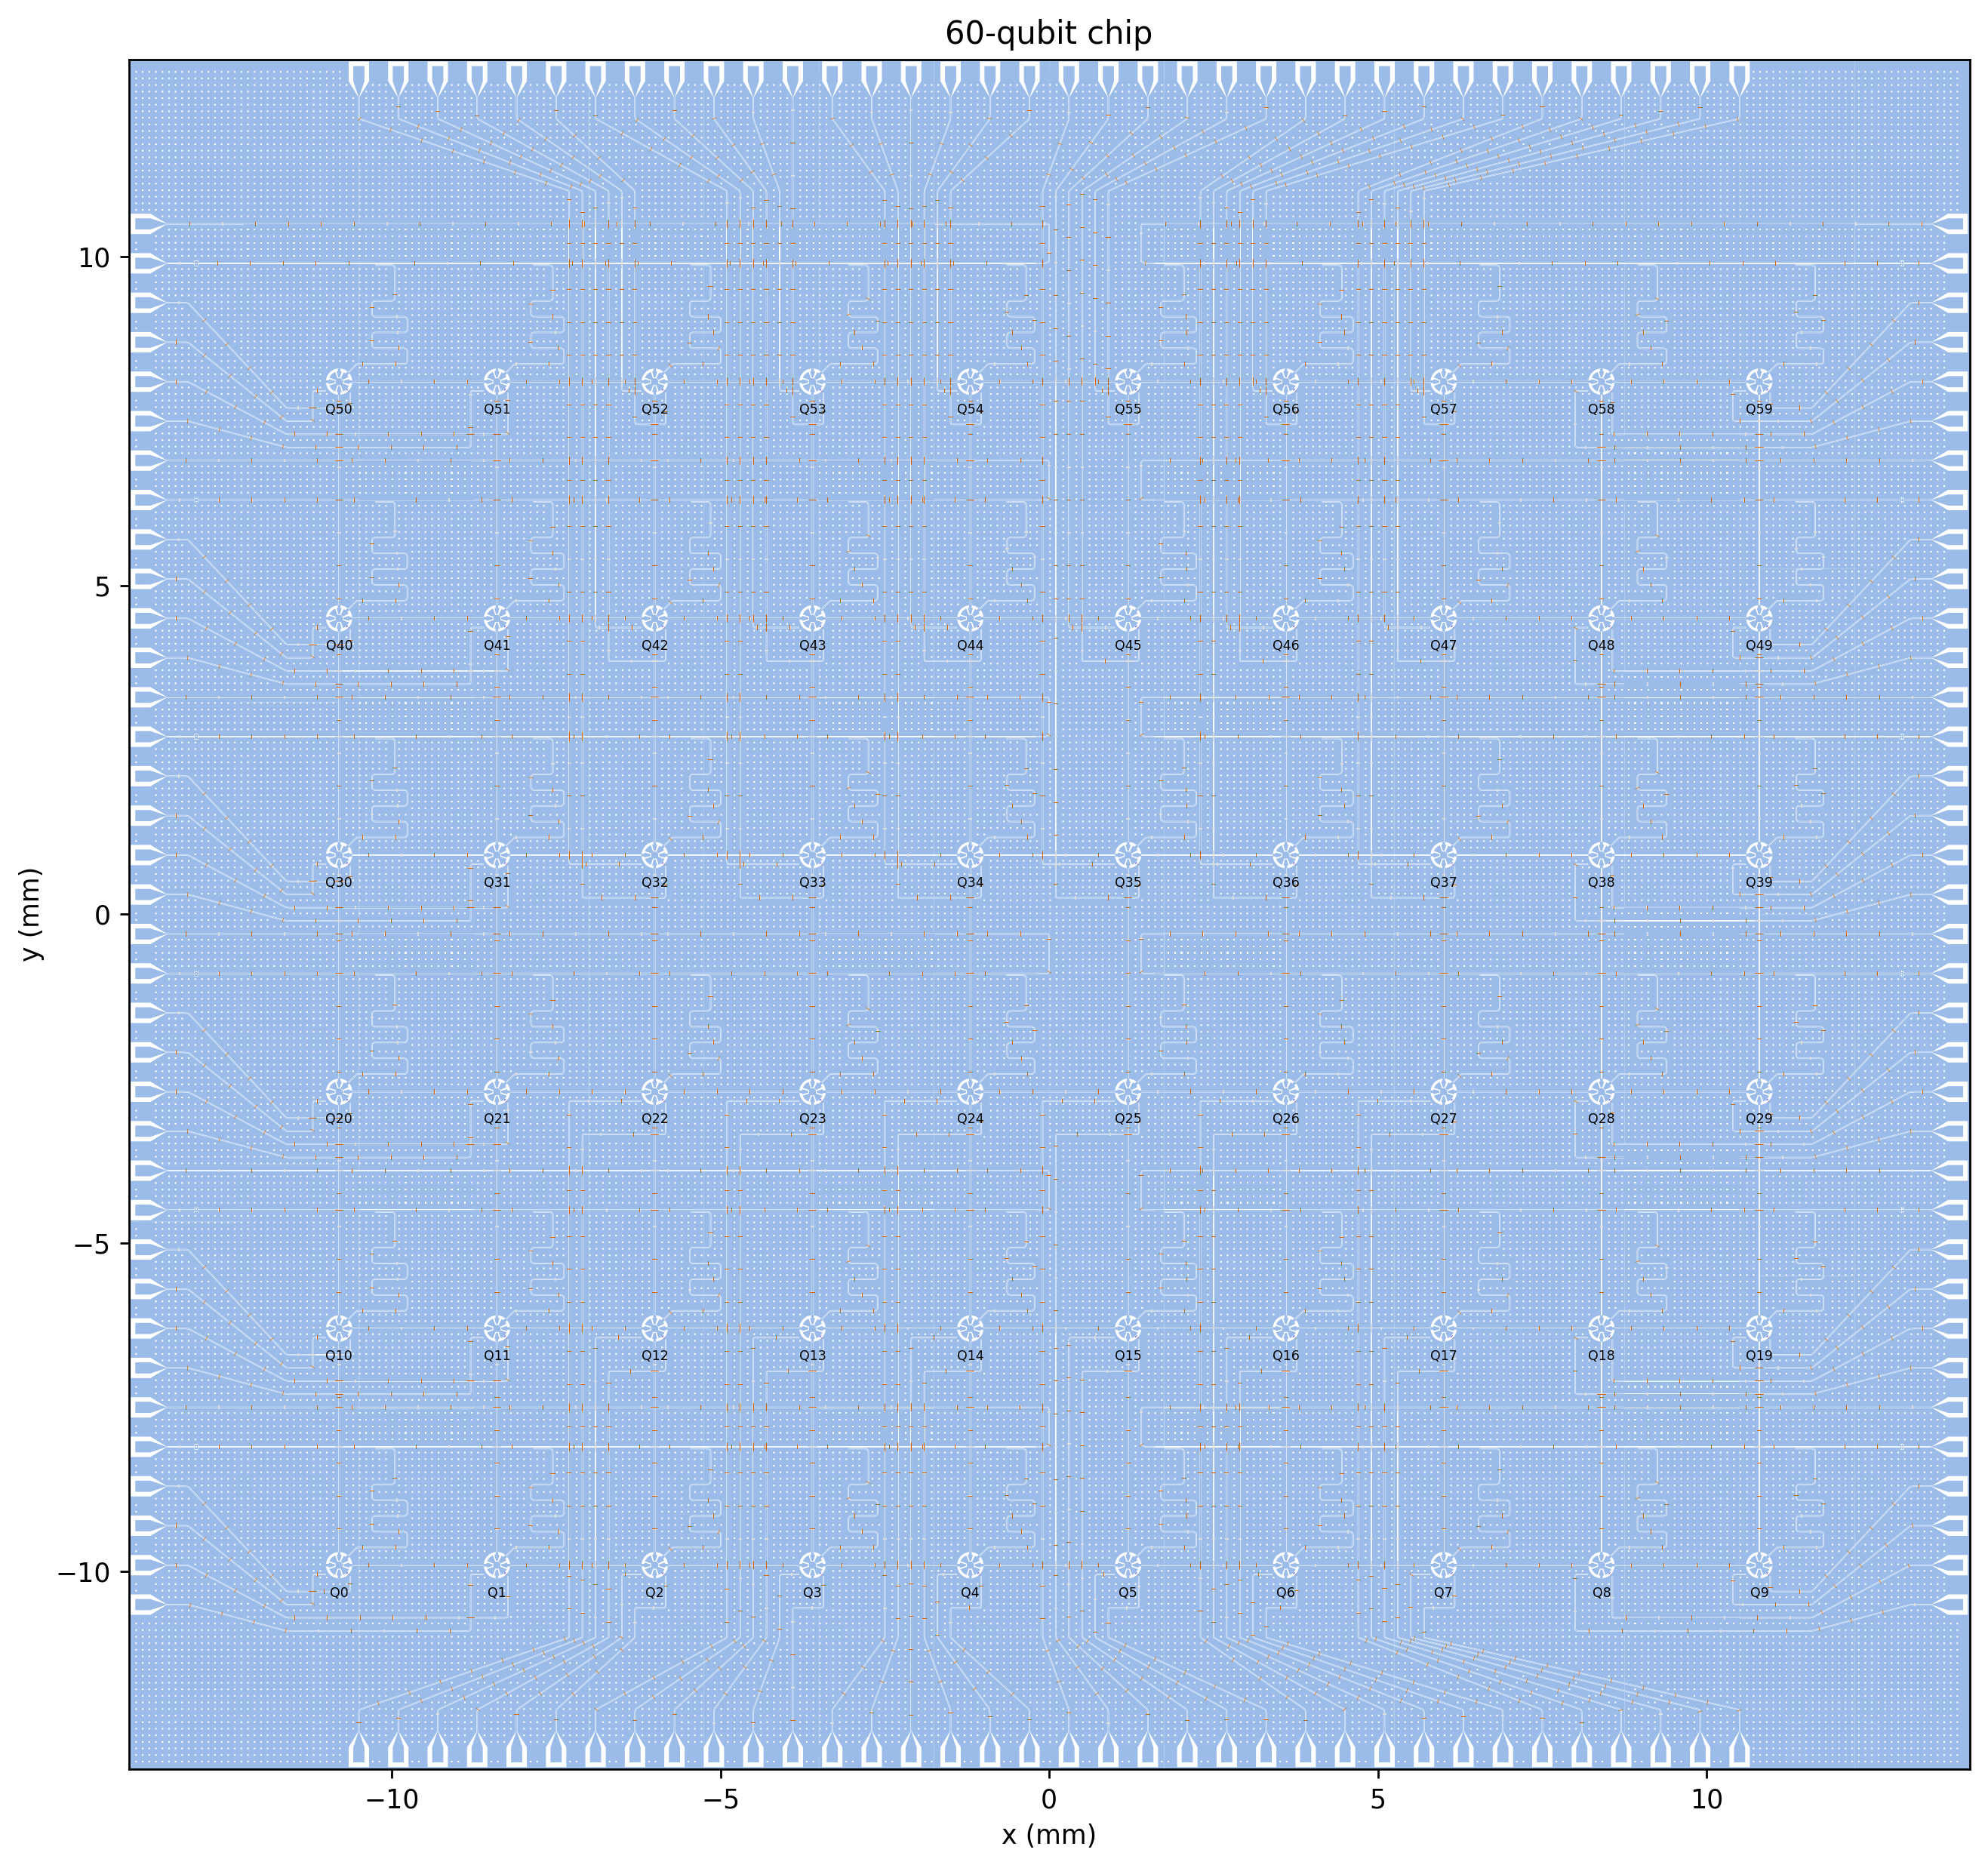

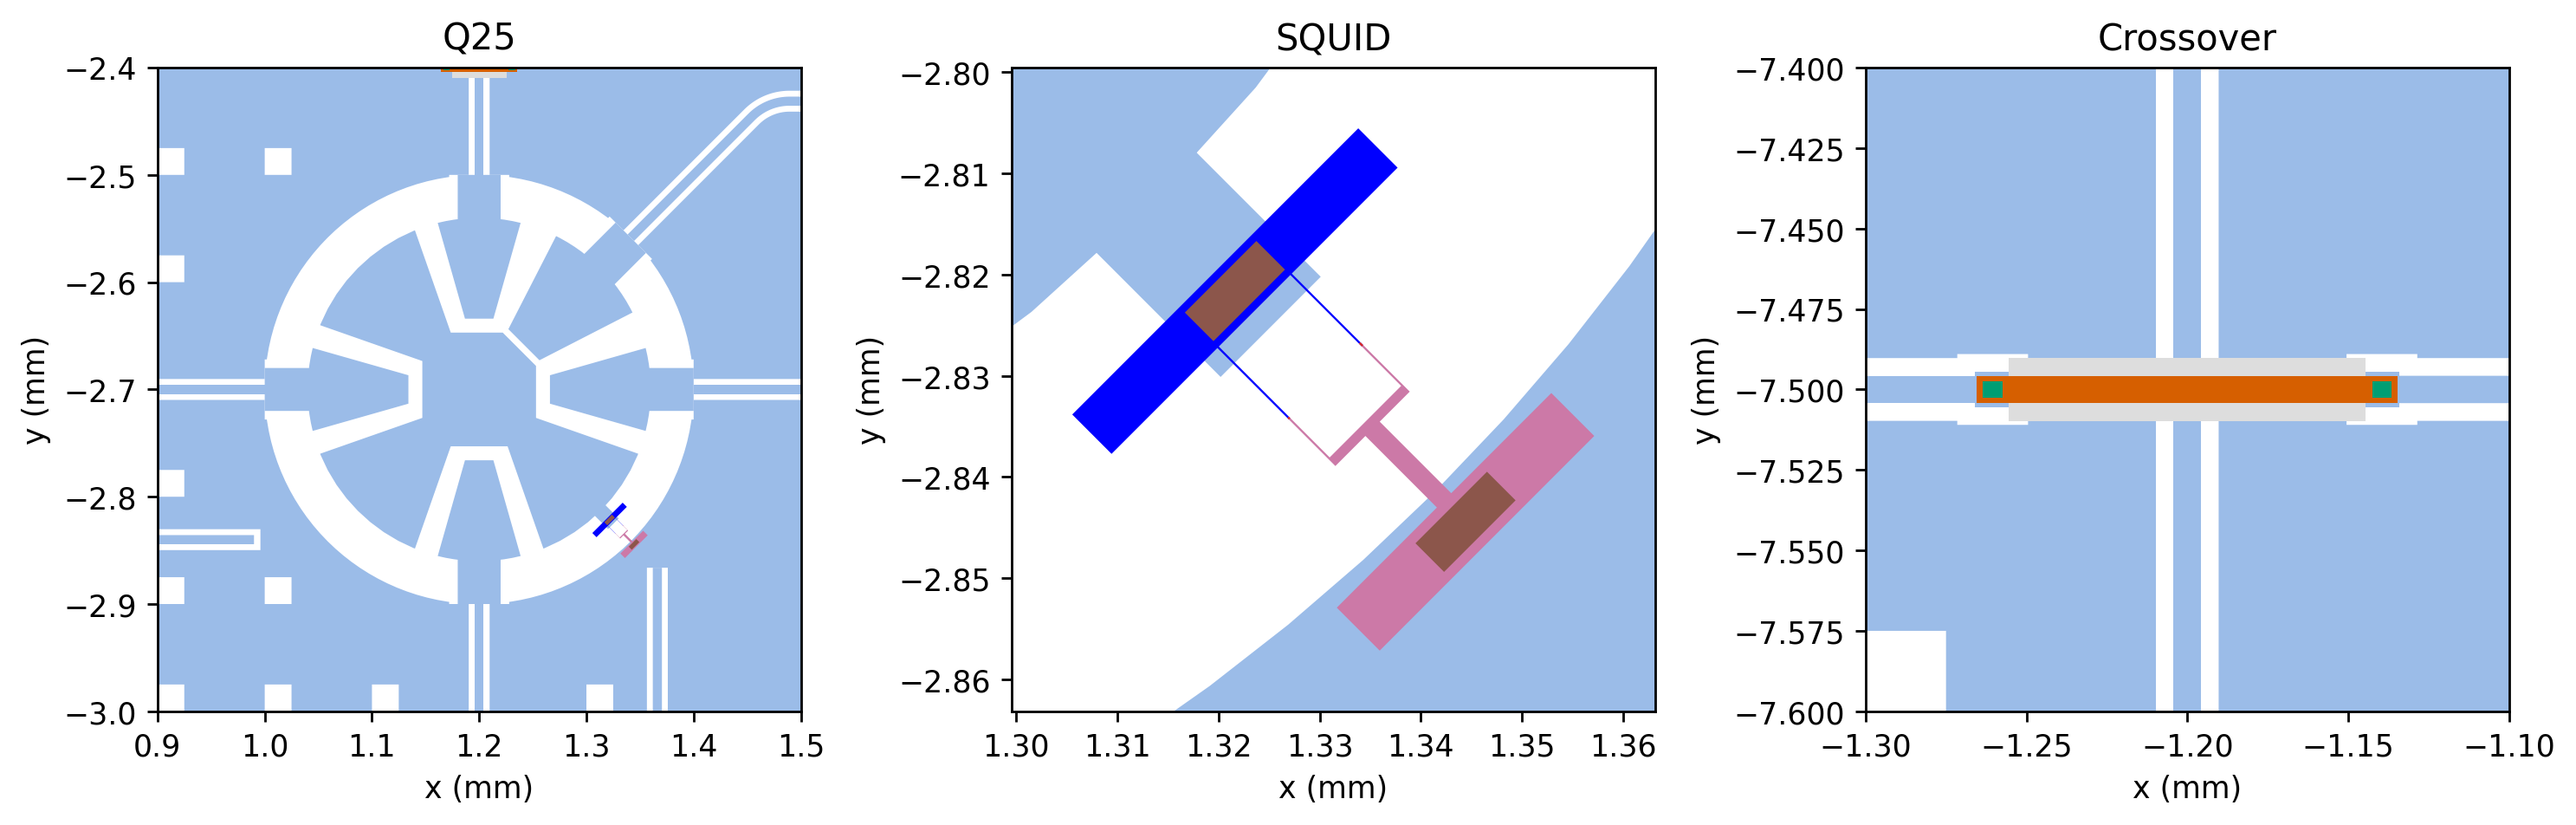

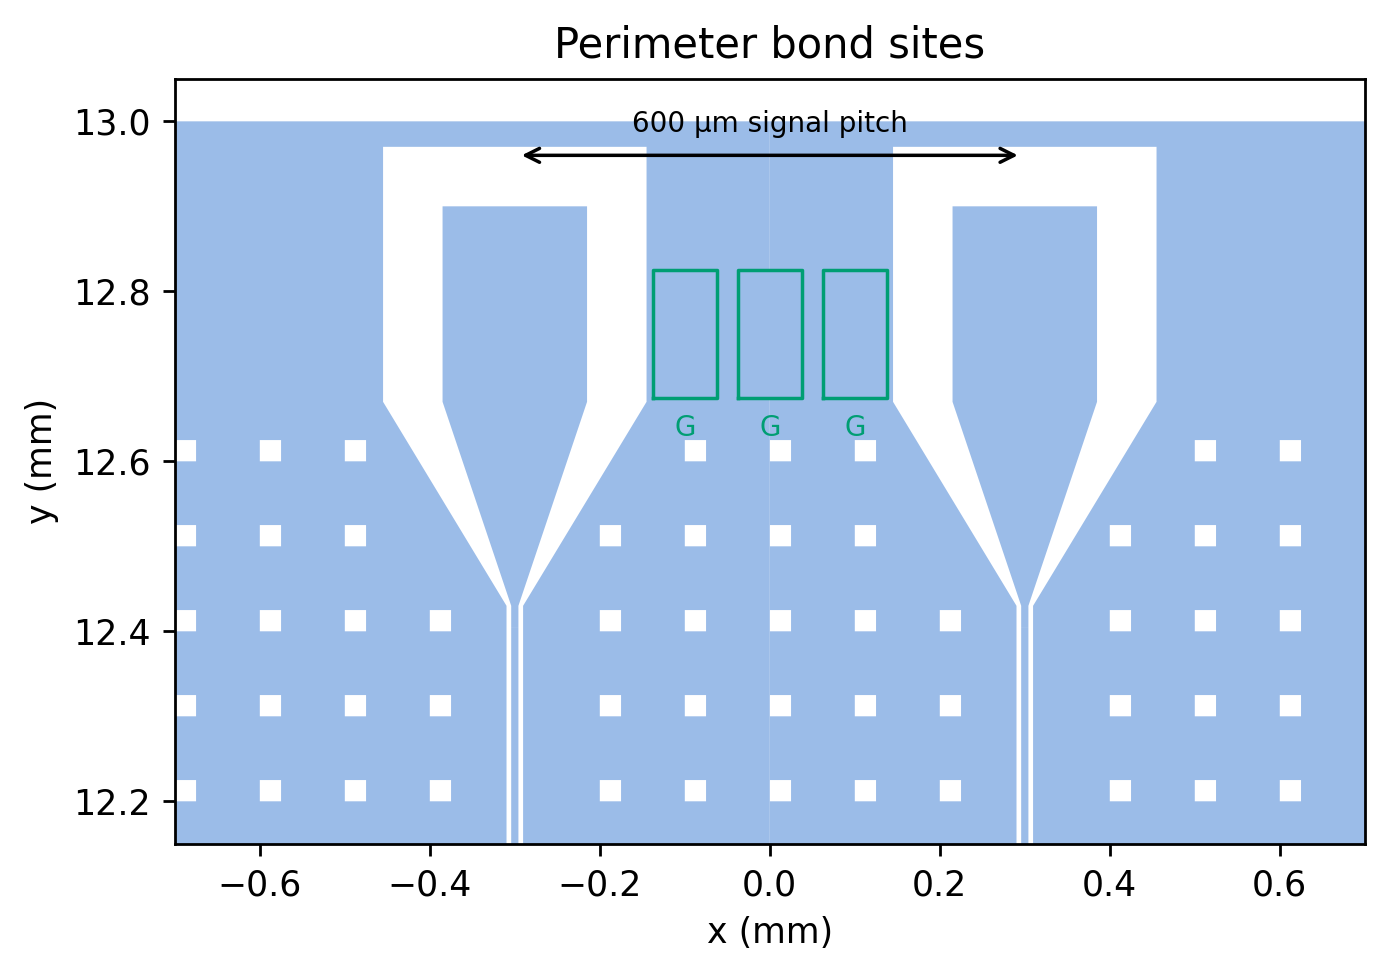

In [15]:
# --- Full-Chip GDS Preview ---
colors = {
    1: "#9bbce8",
    2: "#dddddd",
    3: "#d65f00",
    4: "#009e73",
    5: "#0000ff",
    6: "#cc79a7",
    7: "#d62728",
    8: "#8c564b",
}
fig, ax = plt.subplots(figsize=(12, 10), dpi=250)
for layer, color in colors.items():
    ax.add_collection(
        PolyCollection(
            [p.points for p in exported_polygons if p.layer == layer],
            facecolor=color,
            edgecolor="none",
            rasterized=True,
        )
    )
for q in qubits:
    ax.text(
        float(q.p.pos_x),
        float(q.p.pos_y) - 0.32,
        q.name,
        ha="center",
        va="top",
        fontsize=5,
        fontfamily="DejaVu Sans",
        weight="normal",
    )
ax.set(xlim=(-chip_x / 2, chip_x / 2), ylim=(-chip_y / 2, chip_y / 2), aspect="equal")
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_title("60-qubit chip", fontfamily="DejaVu Sans", weight="normal")
fig.tight_layout()
plt.show()

# --- Component Details ---
q = qubits[25]
squid = design.components[f"SQUID_{q.name}"]
qx, qy = float(q.p.pos_x), float(q.p.pos_y)
sxmin, symin, sxmax, symax = squid.qgeometry_bounds()
crossing = crossings[0]
cx, cy = float(crossing.p.pos_x), float(crossing.p.pos_y)
views = [
    ((qx - 0.30, qx + 0.30), (qy - 0.30, qy + 0.30), q.name),
    ((sxmin - 0.006, sxmax + 0.006), (symin - 0.006, symax + 0.006), "SQUID"),
    ((cx - 0.10, cx + 0.10), (cy - 0.10, cy + 0.10), "Crossover"),
]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=250)
for ax, (xlim, ylim, title) in zip(axes, views):
    for layer, color in colors.items():
        ax.add_collection(
            PolyCollection(
                [p.points for p in exported_polygons if p.layer == layer],
                facecolor=color,
                edgecolor="none",
                rasterized=True,
            )
        )
    ax.set(xlim=xlim, ylim=ylim, aspect="equal")
    ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_title(title, fontfamily="DejaVu Sans", weight="normal")
    ax.ticklabel_format(useOffset=False)
fig.tight_layout()
plt.show()

# --- Perimeter Bonding Detail ---
fig, ax = plt.subplots(figsize=(10, 4), dpi=250)
ax.add_collection(
    PolyCollection(
        [p.points for p in exported_polygons if p.layer == 1],
        facecolor=colors[1],
        edgecolor="none",
        rasterized=True,
    )
)
for name, landing in bond_lands.items():
    if name.startswith("GND_top_") and abs(landing.centroid.x) < 0.15:
        points = np.asarray(landing.exterior.coords)
        ax.plot(points[:, 0], points[:, 1], color="#009e73", linewidth=1)
        ax.text(
            landing.centroid.x,
            chip_y / 2 - 0.37,
            "G",
            ha="center",
            fontsize=8,
            color="#009e73",
            fontfamily="DejaVu Sans",
            weight="normal",
        )
ax.annotate(
    "",
    xy=(-pad_pitch / 2, chip_y / 2 - 0.04),
    xytext=(pad_pitch / 2, chip_y / 2 - 0.04),
    arrowprops=dict(arrowstyle="<->", color="black"),
)
ax.text(
    0,
    chip_y / 2 - 0.02,
    f"{pad_pitch * 1000:g} µm signal pitch",
    ha="center",
    va="bottom",
    fontsize=8,
    fontfamily="DejaVu Sans",
    weight="normal",
)
ax.set(xlim=(-0.7, 0.7), ylim=(chip_y / 2 - 0.85, chip_y / 2 + 0.05), aspect="equal")
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_title("Perimeter bond sites", fontfamily="DejaVu Sans", weight="normal")
ax.ticklabel_format(useOffset=False)
fig.tight_layout()
plt.show()

## References

1. Krinner, S., Lacroix, N., Remm, A. *et al.* (2022) 'Realizing repeated quantum error correction in a distance-three surface code', *Nature*, 605, pp. 669–674. https://doi.org/10.1038/s41586-022-04566-8
2. Koch, J., Yu, T. M., Gambetta, J. *et al.* (2007) 'Charge-insensitive qubit design derived from the Cooper pair box', *Physical Review A*, 76, 042319. https://doi.org/10.1103/PhysRevA.76.042319
3. Blais, A., Grimsmo, A. L., Girvin, S. M. and Wallraff, A. (2021) 'Circuit quantum electrodynamics', *Reviews of Modern Physics*, 93, 025005. https://doi.org/10.1103/RevModPhys.93.025005
4. Huang, S., Lienhard, B., Calusine, G. *et al.* (2021) 'Microwave package design for superconducting quantum processors', *PRX Quantum*, 2, 020306. https://doi.org/10.1103/PRXQuantum.2.020306
5. CERN Bond Lab (n.d.) 'Recommendations for the design of hybrids'. https://bondlab.web.cern.ch/Recommendations.html
6. Integra Technologies (2024) *Assembly guidelines*, September, p. 33, aluminium wedge-bond design guide. https://www.integra-tech.com/uploads/ac5fe383-8aff-4c4e-9950-a0a1abb8091d/Integra-Assembly-Guidelines-September-2024.pdf

Geometry and process conventions follow the supplied **Wallraff_17Q_Revised_by_OJB_Colab** notebook. The **60 to 200 Qubits: Quantum Buses or Tunable Couplers or Not** planning note informs the choice of local connectivity. Component and renderer documentation: [Quantum Metal](https://qiskit-community.github.io/qiskit-metal/).